# Klasifikasi Penggunaan dan Tutupan Lahan (Land Use / Land Cover)
### Citra Sentinel-2A + Algoritma Naive Bayes & K-Nearest Neighbors (KNN)

**Mata Kuliah:** Penambangan Data Sains (*Data Mining*)

---

## 1. Business Understanding (Pemahaman Bisnis)

**Latar Belakang**
Pemetaan tutupan lahan (*Land Cover*) sangat krusial untuk berbagai kepentingan analisis ruang, pengelolaan lingkungan, hingga perencanaan kota. Proses klasifikasi citra satelit multispektral (seperti Sentinel-2A) secara manual memakan waktu yang sangat lama. Oleh karena itu, kita memanfaatkan *Machine Learning* untuk mendeteksi secara otomatis.

**Tujuan**
1. Membangun model machine learning untuk mengklasifikasikan wilayah menjadi beberapa kelas (seperti Sawah, Bangunan, Mangrove, Hutan, Laut, dan Danau).
2. Membandingkan performa antara metode **Naive Bayes** dan **K-Nearest Neighbors (KNN)**.
3. Memvisualisasikan keseluruhan hasil klasifikasi/digitasi yang terpetakan ke dalam *interactive map* (Folium).


In [9]:
import json
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shapely
from shapely.geometry import shape
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

DATASET_NAME = "piksel_s2_JTM.csv"
POLIGON_LAUT_DIKECUALIKAN = {f"Laut_{index:04d}" for index in range(19)}


def cari_dataset():
    for folder in (Path.cwd(), *Path.cwd().parents):
        for kandidat in (folder / DATASET_NAME, folder / "Tugas" / "UTS" / DATASET_NAME):
            if kandidat.is_file():
                return kandidat
    raise FileNotFoundError(
        f"{DATASET_NAME} tidak ditemukan. Simpan dataset di folder notebook "
        "atau di Tugas/UTS dalam folder proyek."
    )


FILE_CSV = cari_dataset()
OUTPUT_DIR = FILE_CSV.parent
BOUNDARY_PATH = FILE_CSV.with_name("batas_jawa_timur.geojson")
if not BOUNDARY_PATH.is_file():
    raise FileNotFoundError(f"Batas Jawa Timur tidak ditemukan: {BOUNDARY_PATH}")
with BOUNDARY_PATH.open(encoding="utf-8") as file:
    boundary_feature = json.load(file)
if boundary_feature.get("properties", {}).get("adm1_pcode") != "ID35":
    raise ValueError("Berkas geometri bukan batas Provinsi Jawa Timur.")
BOUNDARY = shape(boundary_feature["geometry"])
if BOUNDARY.is_empty or not BOUNDARY.is_valid:
    raise ValueError("Geometri batas Provinsi Jawa Timur tidak valid.")

def filter_points_inside_boundary(data):
    coordinates = data[["lon", "lat"]].to_numpy(dtype=np.float64)
    finite_coordinates = np.isfinite(coordinates).all(axis=1)
    inside = np.zeros(len(data), dtype=bool)
    inside[finite_coordinates] = shapely.contains_xy(
        BOUNDARY,
        coordinates[finite_coordinates, 0],
        coordinates[finite_coordinates, 1],
    )
    keep_laut = data["label_teks"].eq("Laut").to_numpy()
    keep_polygon = ~data["poligon_id"].isin(POLIGON_LAUT_DIKECUALIKAN).to_numpy()
    return data.loc[finite_coordinates & keep_polygon & (inside | keep_laut)].copy()


---
## 2. Data Understanding (Pengumpulan & Pemahaman Data)
Kita akan memuat dataset citra satelit hasil ekstraksi (berisi nilai band spektral asli dan indeks turunan seperti NDVI, NDWI, dll).


In [10]:
# Memuat dataset proyek dari path yang ditemukan secara otomatis.
df = pd.read_csv(FILE_CSV)

kolom_wajib = [
    "poligon_id", "label", "label_teks", "lon", "lat",
    "B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI", "MNDWI", "NDBI",
]
kolom_hilang = sorted(set(kolom_wajib) - set(df.columns))
if kolom_hilang:
    raise ValueError(f"Kolom wajib tidak ditemukan di {FILE_CSV.name}: {kolom_hilang}")

baris_dikecualikan = df["poligon_id"].isin(POLIGON_LAUT_DIKECUALIKAN)
jumlah_dikecualikan = int(baris_dikecualikan.sum())
df = filter_points_inside_boundary(df)

print(f"Dataset: {FILE_CSV}")
print(f"Baris piksel Laut dikecualikan: {jumlah_dikecualikan:,}")
print(f"Jumlah baris setelah filter: {df.shape[0]:,}")
print(f"Jumlah kolom: {df.shape[1]}")
df.head()


Dataset: d:\SEMESTER 5\PSD\TUGAS\Tugas\UTS\piksel_s2_JTM.csv
Baris piksel Laut dikecualikan: 58,000
Jumlah baris setelah filter: 562,526
Jumlah kolom: 19


,poligon_id,poligon_no,sampel_id,tile_id,label,label_teks,px_row,px_col,lon,lat,B02,B03,B04,B08,B11,NDVI,NDWI,MNDWI,NDBI
0,Sawah_0000,0,0,x570_y-42,1,Sawah,374,119,114.100652,-8.312431,366.0,532.0,332.0,2903.0,1310.0,0.794745,-0.690247,-0.422367,-0.378115
1,Sawah_0000,0,0,x570_y-42,1,Sawah,375,119,114.100653,-8.312521,457.0,587.0,375.0,3125.0,1448.0,0.785714,-0.683728,-0.423096,-0.366718
2,Sawah_0000,0,0,x570_y-42,1,Sawah,375,120,114.100743,-8.312520,440.0,572.0,349.0,3015.0,1448.0,0.792509,-0.681071,-0.433663,-0.351109
3,Sawah_0000,0,0,x570_y-42,1,Sawah,375,121,114.100834,-8.312519,427.0,552.0,335.0,3020.0,1432.0,0.800298,-0.690929,-0.443548,-0.356694
4,Sawah_0000,0,0,x570_y-42,1,Sawah,375,122,114.100925,-8.312519,465.0,599.0,354.0,3315.0,1432.0,0.807032,-0.693919,-0.410143,-0.396672


---
## 3. Exploratory Data Analysis (EDA)
Melihat distribusi kelas dan perbandingan karakteristik beberapa indeks spektral antar kelas.


C:\Users\hp\AppData\Local\Temp\ipykernel_4620\586167506.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='label_teks', data=df, palette='viridis', order=df['label_teks'].value_counts().index)


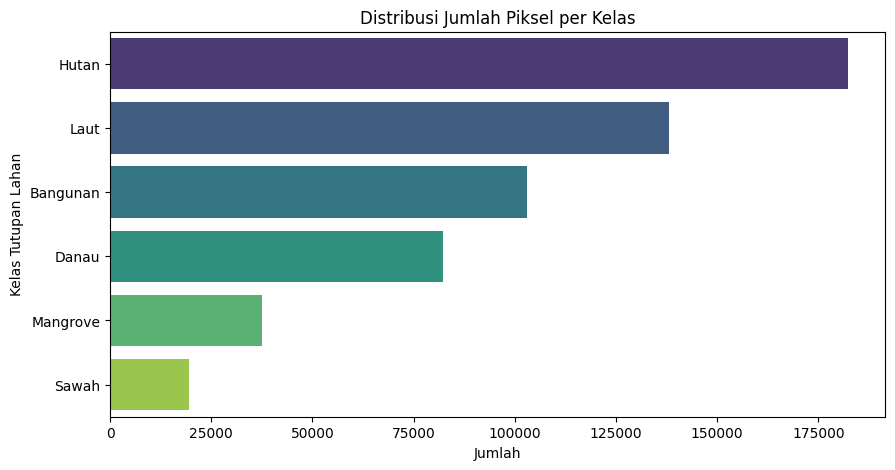

In [11]:
# Distribusi Kelas
plt.figure(figsize=(10, 5))
sns.countplot(y='label_teks', data=df, palette='viridis', order=df['label_teks'].value_counts().index)
plt.title('Distribusi Jumlah Piksel per Kelas')
plt.xlabel('Jumlah')
plt.ylabel('Kelas Tutupan Lahan')
plt.show()


C:\Users\hp\AppData\Local\Temp\ipykernel_4620\1308227807.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')


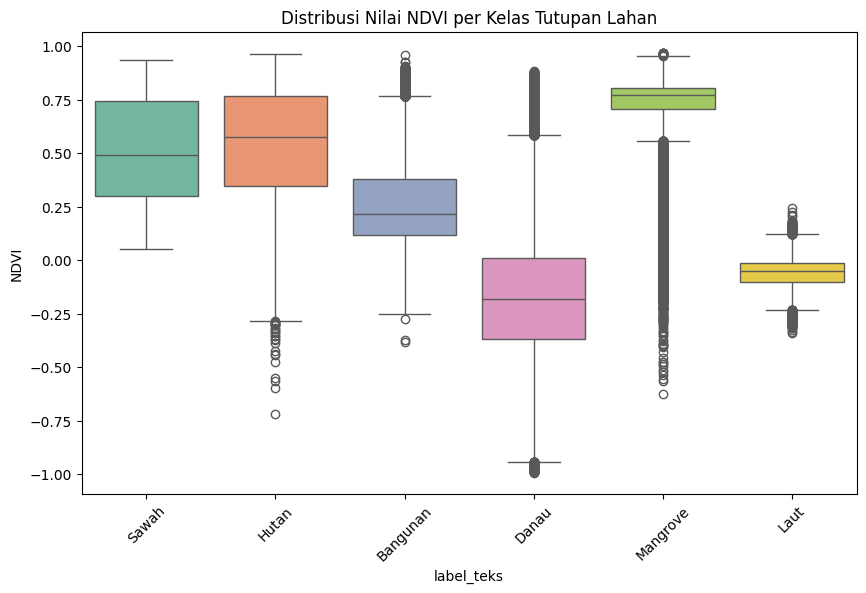

In [12]:
# Boxplot NDVI (Kerapatan Vegetasi) per Kelas
plt.figure(figsize=(10, 6))
sns.boxplot(x='label_teks', y='NDVI', data=df, palette='Set2')
plt.title('Distribusi Nilai NDVI per Kelas Tutupan Lahan')
plt.xticks(rotation=45)
plt.show()


---
## 4. Preprocessing Data
Membagi data menjadi variabel fitur (X) dan target (y), memisahkan data *training* dan *testing*, lalu melakukan standarisasi (*scaling*).


In [13]:
# Satu observasi per poligon untuk mencegah kebocoran piksel ke train dan test.
fitur = ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI", "MNDWI", "NDBI"]
kolom_agregasi = ["poligon_id", "label", "label_teks", "lon", "lat", *fitur]
df_bersih = df[kolom_agregasi].replace([np.inf, -np.inf], np.nan).dropna().copy()

poligon = (
    df_bersih.groupby("poligon_id", as_index=False)
    .agg(
        label=("label", "first"),
        label_teks=("label_teks", "first"),
        lon=("lon", "mean"),
        lat=("lat", "mean"),
        **{nama_fitur: (nama_fitur, "mean") for nama_fitur in fitur},
    )
)

poligon = filter_points_inside_boundary(poligon)

X = poligon[fitur]
y = poligon["label_teks"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah poligon: {len(poligon):,}")
print(f"Jumlah data latih: {len(X_train):,}")
print(f"Jumlah data uji: {len(X_test):,}")


Jumlah poligon: 278
Jumlah data latih: 194
Jumlah data uji: 84


---
## 5. Pemodelan (Modeling & Evaluasi)
### 5.1 Naive Bayes (Gaussian)


In [14]:
# Pelatihan dan evaluasi Naive Bayes pada data uji tingkat poligon.
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)
y_pred_nb = nb_model.predict(X_test_scaled)

print("=== HASIL EVALUASI NAIVE BAYES ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_nb) * 100:.2f}%")
print("Classification Report:\n", classification_report(y_test, y_pred_nb, zero_division=0))


=== HASIL EVALUASI NAIVE BAYES ===
Akurasi: 71.43%
Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.76      0.87      0.81        15
       Danau       0.83      0.67      0.74        15
       Hutan       0.71      0.80      0.75        15
        Laut       0.80      0.89      0.84         9
    Mangrove       0.65      0.73      0.69        15
       Sawah       0.55      0.40      0.46        15

    accuracy                           0.71        84
   macro avg       0.72      0.73      0.72        84
weighted avg       0.71      0.71      0.71        84



### 5.2 K-Nearest Neighbors (KNN)


In [15]:
# Pelatihan dan evaluasi K-Nearest Neighbors pada data uji tingkat poligon.
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

print("=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN) ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_knn) * 100:.2f}%")
print("Classification Report:\n", classification_report(y_test, y_pred_knn, zero_division=0))


=== HASIL EVALUASI K-NEAREST NEIGHBORS (KNN) ===
Akurasi: 73.81%
Classification Report:
               precision    recall  f1-score   support

    Bangunan       0.71      0.80      0.75        15
       Danau       0.91      0.67      0.77        15
       Hutan       0.64      0.93      0.76        15
        Laut       0.90      1.00      0.95         9
    Mangrove       0.85      0.73      0.79        15
       Sawah       0.55      0.40      0.46        15

    accuracy                           0.74        84
   macro avg       0.76      0.76      0.75        84
weighted avg       0.75      0.74      0.73        84



---
## 6. Visualisasi Peta Hasil Klasifikasi / Digitasi
Memetakan seluruh titik hasil digitasi ke dalam peta **Folium** menggunakan pendekatan *Convex Hull* agar peta berjalan dengan ringan dan keseluruhan area terlihat sebagai satu kesatuan poligon.


In [16]:
# Peta sebaran sampel per poligon berdasarkan koordinat pada dataset.
warna = {
    "Sawah": "#FFD92F",
    "Bangunan": "#E41A1C",
    "Mangrove": "#8E44AD",
    "Lahan Hijau": "#2E7D32",
    "Laut": "#0D47A1",
    "Danau": "#4FC3F7",
}

peta = folium.Map(
    location=[poligon["lat"].mean(), poligon["lon"].mean()],
    zoom_start=6,
    tiles="OpenStreetMap",
)
for kelas in sorted(poligon["label_teks"].dropna().unique()):
    layer = folium.FeatureGroup(name=str(kelas))
    warna_kelas = warna.get(str(kelas), "#333333")
    for row in poligon[poligon["label_teks"] == kelas].itertuples():
        folium.CircleMarker(
            location=[row.lat, row.lon],
            radius=5,
            color=warna_kelas,
            fill=True,
            fill_color=warna_kelas,
            fill_opacity=0.8,
            tooltip=f"{row.poligon_id} | Kelas: {row.label_teks}",
        ).add_to(layer)
    layer.add_to(peta)

folium.LayerControl(collapsed=False).add_to(peta)
FILE_PETA = OUTPUT_DIR / "peta_sampel_JTM.html"
peta.save(str(FILE_PETA))
print(f"Peta sampel tersimpan: {FILE_PETA}")
peta


Peta sampel tersimpan: d:\SEMESTER 5\PSD\TUGAS\Tugas\UTS\peta_sampel_JTM.html
